# PASO 3: Modelos Supervizados - Regresión

### 1\. Definición del Target y las Features

-   **Variable Objetivo (Target):** Nuestra variable a predecir será `salario` (antiguamente `_sal`) que representa el salario bruto y sin extremos.

-   **Variables Predictoras (Features):** Debemos seleccionar qué columnas del dataset aportan valor real para explicar el sueldo, separándolas en numéricas y categóricas:

    -   *Numéricas clave:* `sueldo_dolarizado`, `anos_de_experiencia`, `antiguedad_en_la_empresa_actual`, `anos_en_el_puesto_actual`, `tengo_edad`, `salario`, `es_jerarquico`.

    -   *Categóricas clave:* `donde_estas_trabajando`, `dedicacion`, `tipo_de_contrato`, `modalidad_de_trabajo`, `contas_con_beneficios_adicionales`, `estas_buscando_trabajo`, `tenes_guardias`, `trabajo_de`, `seniority`, `plataformas_que_utilizas_en_tu_puesto_actual`, `lenguajes_de_programacion_o_tecnologias_que_utilices_en_tu_puesto_actual`, `frameworksherramientas_y_librerias_que_utilices_en_tu_puesto_actual`, `bases_de_datos`, `qa_testing`, `cantidad_de_personas_en_tu_organizacion`, `maximo_nivel_de_estudios`, `estado`, `carrera`, `genero`.

In [2]:
# Importa la función desde helpers.py
import sys
import os

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from helpers import formato_moneda

In [3]:
# Carga de librerías esenciales y DataFrame
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MultiLabelBinarizer

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

# Importamos el dataset con features ya procesadas
df = pd.read_csv('../data/dataset_features.csv')
display(df.head(3))

,anos_de_experiencia,antiguedad_en_la_empresa_actual,anos_en_el_puesto_actual,tengo_edad,donde_estas_trabajando_Buenos Aires,donde_estas_trabajando_Catamarca,donde_estas_trabajando_Chaco,donde_estas_trabajando_Chubut,donde_estas_trabajando_Ciudad Autónoma De Buenos Aires,donde_estas_trabajando_Corrientes,...,qa_testing__No Aplica,qa_testing__Zephyr,qa_testing__Karate,qa_testing__K6,qa_testing__Hp Loadrunner,qa_testing__Swagger,qa_testing__Webdriverio,qa_testing__No Uso,qa_testing__Frontier,salario
0,0.613263,-0.289608,-0.153412,0.894996,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,3000000.0
1,1.846085,1.419854,2.189779,1.461241,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5000000.0
2,-0.372994,-0.669488,0.888007,-0.124246,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4600000.0


In [4]:
# 2. Definimos X_final y variable target
X_final = df.drop(columns=['salario']) 
y = df['salario']

### 2\. Modelado predictivo

Separación de entrenamiento y prueba, entrenamiento de modelos y comparación de resultados.

#### Armamos conjunto de Train y Test (80% / 20%)

Se eligio una división del 80% para entrenamiento y del 20% test, ya que es una de las más utilizadas . De esta manera, el modelo puede aprender a partir de la mayor parte de los datos y evaluar su rendimiento con datos que no vio durante el entrenamiento.

In [5]:
# 1. Separamos los datos: 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y,
    test_size=0.20,
    random_state=42
)

# 2. Mostramos las dimensiones de cada conjunto
print("ENTRENAMIENTO")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPRUEBA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# 3. Analizamos el salario del conjunto de entrenamiento
print("\nESTADÍSTICAS DEL SALARIO EN TRAIN")
print(f"Media:   ${y_train.mean():,.2f}")
print(f"Mediana: ${y_train.median():,.2f}")
print(f"Mínimo:  ${y_train.min():,.2f}")
print(f"Máximo:  ${y_train.max():,.2f}")

ENTRENAMIENTO
X_train: (3509, 752)
y_train: (3509,)

PRUEBA
X_test: (878, 752)
y_test: (878,)

ESTADÍSTICAS DEL SALARIO EN TRAIN
Media:   $3,652,023.90
Mediana: $3,244,268.32
Mínimo:  $750,000.00
Máximo:  $10,355,004.00


#### Modelos a usar

| Modelo | Cómo aprende | Complejidad |
|---|---|---|
| Dummy Regressor | Predice siempre la media salarial | Mínima |
| Regresión Lineal | Aprende una combinación lineal de variables | Baja |
| Random Forest | Pormedia predicciones de muchos árboles | Alta |
| HistGradientBoosting | Construye árboles sucesivos para mejorar las predicciones | Alta |

Métricas a usar:
* **MAE**: error absoluto promedio. Si es menor, las predicciones suelen estar más cerca del salario real.
* **RMSE**: penaliza especialmente los errores grandes. También conviene que sea menor.
* **R²**: mide cuánto de la variabilidad de los salarios logra explicar el modelo. Cuanto más cerca de 1, mejor; puede ser negativo si predice peor que usar la media de referencia.

#### Modelo de referencia (Dummy) y Regresión Lineal

Primero entrenamos y comparamos estos dos modelos para predecir el salario bruto a partir de las variables disponibles en el dataset.

**Dummy** funciona como modelo de referencia mientras que **LinearRegression** busca aprender una relación lineal entre las variables predictoras y el salario.

In [6]:
# 1. Modelo de referencia: predice la media de y_train
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_train, y_train)

# 2. Regresión lineal
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

# 3. Generamos predicciones sobre los datos de prueba
pred_dummy = modelo_dummy.predict(X_test)
pred_lineal = modelo_lineal.predict(X_test)

# 4. Evaluamos ambos modelos
def evaluar_modelo(nombre, y_real, y_predicho):
    mae = mean_absolute_error(y_real, y_predicho)
    rmse = np.sqrt(mean_squared_error(y_real, y_predicho))
    r2 = r2_score(y_real, y_predicho)

    return {
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

resultados_lineal = pd.DataFrame([
    evaluar_modelo("DummyRegressor (media)", y_test, pred_dummy),
    evaluar_modelo("Regresión lineal", y_test, pred_lineal)
])

# Creamos una copia formateada para mostrar en pantalla de forma amigable
resultados_display_lineal = resultados_lineal.copy()
resultados_display_lineal["MAE"] = resultados_display_lineal["MAE"].apply(formato_moneda)
resultados_display_lineal["RMSE"] = resultados_display_lineal["RMSE"].apply(formato_moneda)
resultados_display_lineal["R²"] = resultados_display_lineal["R²"].round(2)

display(resultados_display_lineal)

print("SALARIO REAL EN TEST")
print(f"Media:   ${y_test.mean():,.2f}")
print(f"Mediana: ${y_test.median():,.2f}")
print(f"Desvío estándar: ${y_test.std():,.2f}")

print("\nERROR DE LA REGRESIÓN LINEAL")
print(
    f"MAE como % de la media de test: "
    f"{mean_absolute_error(y_test, pred_lineal) / y_test.mean() * 100:.2f}%"
)

,Modelo,MAE,RMSE,R²
0,DummyRegressor (media),"$1.555.696,55","$1.945.969,65",-0.00
1,Regresión lineal,"$1.129.492,49","$1.486.908,71",0.41


SALARIO REAL EN TEST
Media:   $3,741,933.36
Mediana: $3,300,000.00
Desvío estándar: $1,944,999.45

ERROR DE LA REGRESIÓN LINEAL
MAE como % de la media de test: 30.18%


> **Conclusiones**: **LinearRegression** supera al modelo de referencia en las tres métricas: reduce el MAE en aproximadamente un 22,5 % y el RMSE en alrededor de un 18,9 %, además de alcanzar un R² de 0,34.
Esto demuestra que las variables utilizadas contienen información útil para estimar los salarios. Sin embargo, el modelo todavía deja sin explicar una parte importante de su variabilidad. Por lo tanto, resulta conveniente evaluar modelos capaces de representar relaciones no lineales e interacciones entre variables, como los árboles de decisión, Random Forest e HistGradientBoosting, y comparar sus resultados utilizando el mismo conjunto de prueba.

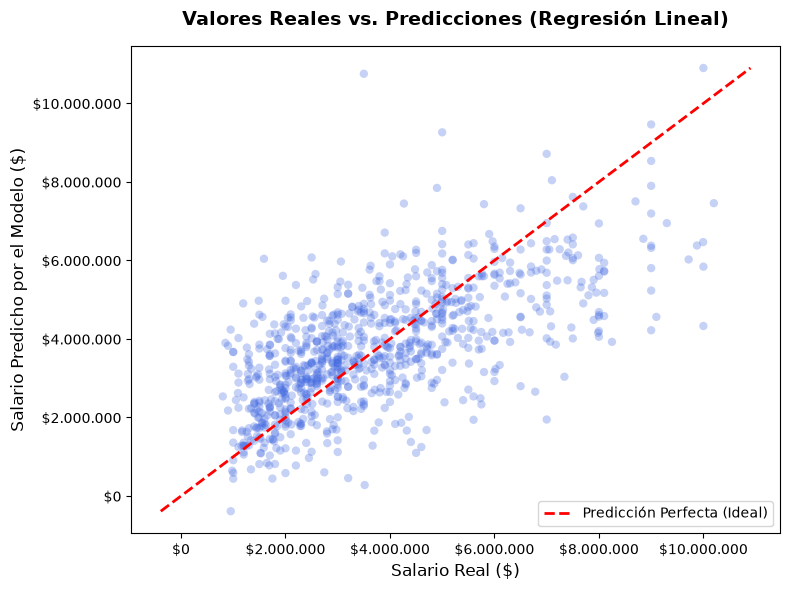

In [7]:
# Gráfico de dispersión: Valores reales vs Predicciones de la Regresión Lineal
plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_lineal, alpha=0.3, color='royalblue', edgecolors='none')

# Línea diagonal de referencia (Predicción perfecta 1 a 1)
min_val = min(y_test.min(), pred_lineal.min())
max_val = max(y_test.max(), pred_lineal.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta (Ideal)')

plt.title('Valores Reales vs. Predicciones (Regresión Lineal)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Salario Real ($)', fontsize=12)
plt.ylabel('Salario Predicho por el Modelo ($)', fontsize=12)

# Formatear ejes con separadores de miles
import matplotlib.ticker as ticker
formatter = ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", "."))
plt.gca().xaxis.set_major_formatter(formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.legend()
plt.tight_layout()
plt.show()

#### Modelo de referencia (Dummy) y Random Forest Regressor

En esta etapa evaluamos el rendimiento de **Random Forest Regressor** frente al modelo de referencia **Dummy Regressor**, utilizando los mismos conjuntos de entrenamiento y prueba.

A diferencia de la regresión lineal, puede identificar relaciones no lineales e interacciones entre las variables, lo que permite representar patrones más complejos en los datos.

In [8]:
# 1. Instanciamos y entrenamos el Modelo Dummy (lo repetimos para mantener el bloque autocontenido)
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_train, y_train)

# 2. Instanciamos y entrenamos el Random Forest Regressor
# Usamos un random_state para que los resultados sean reproducibles
modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# 3. Generamos predicciones sobre los datos de prueba
pred_dummy = modelo_dummy.predict(X_test)
pred_rf = modelo_rf.predict(X_test)

# 4. Evaluamos ambos modelos usando la misma función previa (o la redefinimos por seguridad)
def evaluar_modelo(nombre, y_real, y_predicho):
    mae = mean_absolute_error(y_real, y_predicho)
    rmse = np.sqrt(mean_squared_error(y_real, y_predicho))
    r2 = r2_score(y_real, y_predicho)

    return {
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

# Generamos la tabla comparativa consolidada
resultados_rf = pd.DataFrame([
    evaluar_modelo("DummyRegressor (media)", y_test, pred_dummy),
    evaluar_modelo("Random Forest Regressor", y_test, pred_rf)
])

# Creamos una copia formateada para mostrar en pantalla de forma amigable
resultados_display = resultados_rf.copy()
resultados_display["MAE"] = resultados_display["MAE"].apply(formato_moneda)
resultados_display["RMSE"] = resultados_display["RMSE"].apply(formato_moneda)
resultados_display["R²"] = resultados_display["R²"].round(2)

display(resultados_display)

,Modelo,MAE,RMSE,R²
0,DummyRegressor (media),"$1.555.696,55","$1.945.969,65",-0.00
1,Random Forest Regressor,"$1.017.078,41","$1.361.353,37",0.51


> **Conclusiones**: De los tres modelos evaluados hasta el momento, Random Forest Regressor presenta el mejor rendimiento sobre el conjunto de prueba, ya que obtiene los menores valores de MAE y RMSE, junto con el mayor R².
Sin embargo, el modelo todavía presenta un error absoluto medio cercano a $1.016.760 por predicción y no explica toda la variabilidad salarial. Por eso, conviene evaluar otros modelos y comprobar el rendimiento sobre datos no utilizados durante el entrenamiento antes de seleccionar el modelo definitivo.

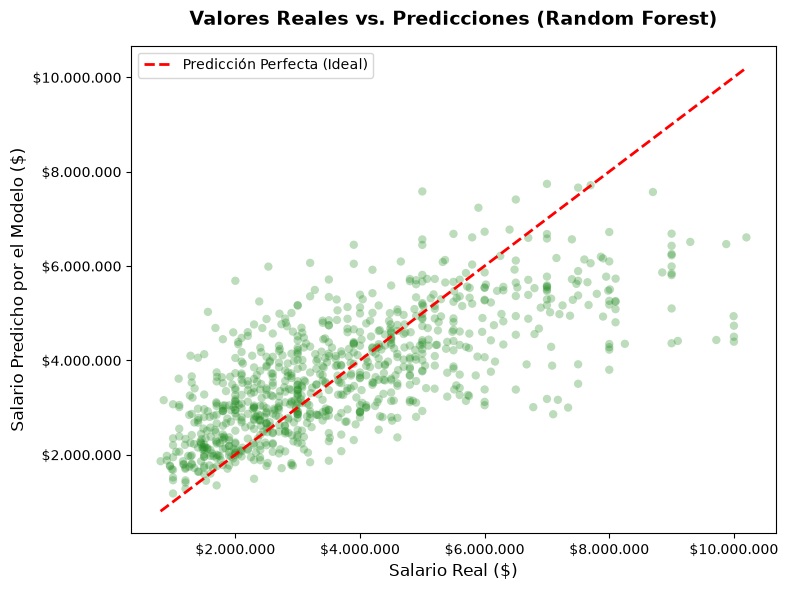

In [9]:
# Gráfico de dispersión para Random Forest
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_rf, alpha=0.3, color='forestgreen', edgecolors='none')

# Línea diagonal de referencia (Predicción perfecta 1 a 1)
min_val = min(y_test.min(), pred_rf.min())
max_val = max(y_test.max(), pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta (Ideal)')

plt.title('Valores Reales vs. Predicciones (Random Forest)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Salario Real ($)', fontsize=12)
plt.ylabel('Salario Predicho por el Modelo ($)', fontsize=12)

# Formatear ejes con separadores de miles
formatter = ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", "."))
plt.gca().xaxis.set_major_formatter(formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.legend()
plt.tight_layout()
plt.show()

#### Modelos de referencia (Dummy) y HistGradientBoosting

En este módulo incorporamos **HistGradientBoosting Regressor** para compararlo con los modelos evaluados anteriormente.

Este modelo construye árboles de decisión de manera secuencial, buscando corregir los errores de las predicciones anteriores. Este enfoque permite capturar relaciones complejas e interacciones entre variables.

In [10]:
# 1. Instanciamos y entrenamos los modelos (incluyendo Dummy, RF y el nuevo HistGB)
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_train, y_train)

modelo_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# HistGradientBoostingRegressor (excelente para capturar interacciones complejas rápidamente)
modelo_hgb = HistGradientBoostingRegressor(random_state=42)
modelo_hgb.fit(X_train, y_train)

# 2. Generamos predicciones sobre el conjunto de prueba
pred_dummy = modelo_dummy.predict(X_test)
pred_rf = modelo_rf.predict(X_test)
pred_hgb = modelo_hgb.predict(X_test)

# 3. Función auxiliar para dar formato de moneda en pesos argentinos
def formatear_moneda(valor):
    return f"${valor:,.0f}".replace(",", ".")

# 4. Función de evaluación unificada
def evaluar_modelo(nombre, y_real, y_predicho):
    mae = mean_absolute_error(y_real, y_predicho)
    rmse = np.sqrt(mean_squared_error(y_real, y_predicho))
    r2 = r2_score(y_real, y_predicho)

    return {
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

# Construimos la tabla comparativa con los tres modelos
resultados_finales = pd.DataFrame([
    evaluar_modelo("DummyRegressor (media)", y_test, pred_dummy),
    evaluar_modelo("Random Forest Regressor", y_test, pred_rf),
    evaluar_modelo("HistGradientBoosting", y_test, pred_hgb)
])

# Creamos la versión formateada para mostrar en pantalla
resultados_display = resultados_finales.copy()
resultados_display["MAE"] = resultados_display["MAE"].apply(formatear_moneda)
resultados_display["RMSE"] = resultados_display["RMSE"].apply(formatear_moneda)
resultados_display["R²"] = resultados_display["R²"].round(2)

display(resultados_display)

,Modelo,MAE,RMSE,R²
0,DummyRegressor (media),$1.555.697,$1.945.970,-0.00
1,Random Forest Regressor,$1.017.078,$1.361.353,0.51
2,HistGradientBoosting,$991.691,$1.337.394,0.53


> Entre los modelos evaluados hasta el momento, HistGradientBoosting presenta las mejores métricas sobre el conjunto de prueba, con un MAE de $996.318, un RMSE de $1.360.146 y un R² de 0,50.
Su mejora respecto de Random Forest es pequeña, pero consistente en las tres métricas. En comparación con la regresión lineal, los resultados sugieren que los modelos basados en árboles logran representar mejor las relaciones presentes en los datos salariales.

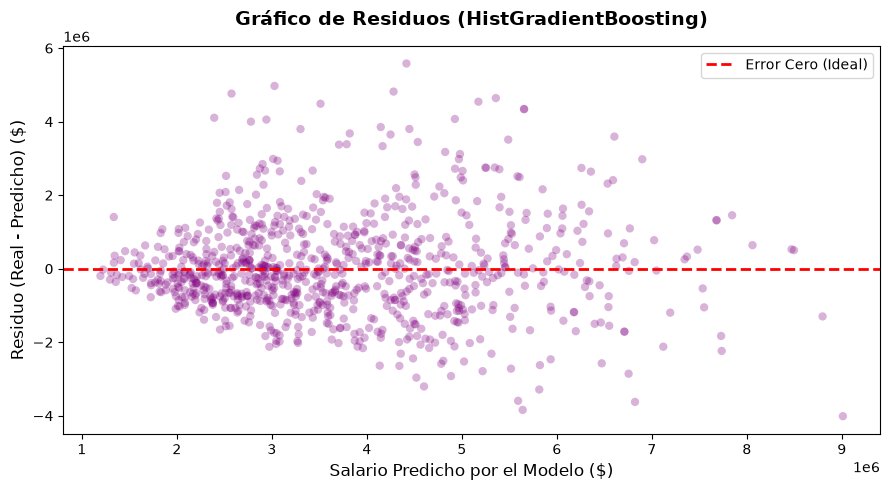

In [11]:
# Calculamos los residuos (lo real menos lo predicho)
residuos = y_test - pred_hgb

plt.figure(figsize=(9, 5))
plt.scatter(pred_hgb, residuos, alpha=0.3, color='purple', edgecolors='none')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Error Cero (Ideal)')

plt.title('Gráfico de Residuos (HistGradientBoosting)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Salario Predicho por el Modelo ($)', fontsize=12)
plt.ylabel('Residuo (Real - Predicho) ($)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

### 4\. Validación Cruzada y Estabilidad de Modelos

En esta etapa buscamos evaluar la estabilidad y la capacidad de generalización de los modelos de predicción salarial mediante validación cruzada.

Aplicaremos una validación cruzada de cinco particiones (5-Fold Cross-Validation) sobre el conjunto de entrenamiento. En cada iteración, cuatro particiones se utilizan para entrenar el modelo y la restante para validarlo. El proceso se repite hasta que todas las particiones hayan sido utilizadas para validación.


In [12]:
# Validación Cruzada de Modelos Supervisados

# 1. Definimos la validación cruzada de 5 particiones
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Definimos los modelos que vamos a comparar
modelos = {
    "DummyRegressor": DummyRegressor(strategy="mean"),
    "Regresión Lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        random_state=42
    )
}

# 3. Definimos las métricas de evaluación
metricas = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# 4. Ejecutamos la validación cruzada
resultados_cv = []

for nombre, modelo in modelos.items():

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=False
    )

    resultados_cv.append({
        "Modelo": nombre,

        "MAE promedio": -scores["test_MAE"].mean(),
        "MAE desvío": scores["test_MAE"].std(),

        "RMSE promedio": -scores["test_RMSE"].mean(),
        "RMSE desvío": scores["test_RMSE"].std(),

        "R² promedio": scores["test_R2"].mean(),
        "R² desvío": scores["test_R2"].std()
    })

# 5. Construimos la tabla con los resultados
tabla_cv = pd.DataFrame(resultados_cv)

# 6. Ordenamos por MAE promedio: menor es mejor
tabla_cv = tabla_cv.sort_values(
    by="MAE promedio"
).reset_index(drop=True)

# 7. Formateamos los resultados para mostrarlos
tabla_cv_display = tabla_cv.copy()

columnas_monetarias = [
    "MAE promedio",
    "MAE desvío",
    "RMSE promedio",
    "RMSE desvío"
]

for col in columnas_monetarias:
    tabla_cv_display[col] = tabla_cv_display[col].apply(
        lambda valor: f"${valor:,.0f}".replace(",", ".")
    )

columnas_r2 = ["R² promedio", "R² desvío"]

for col in columnas_r2:
    tabla_cv_display[col] = tabla_cv_display[col].round(3)

display(tabla_cv_display)


,Modelo,MAE promedio,MAE desvío,RMSE promedio,RMSE desvío,R² promedio,R² desvío
0,HistGradientBoosting,$995.946,$29.896,$1.332.269,$44.383,0.514,0.008
1,Random Forest,$1.025.699,$25.809,$1.367.859,$44.708,0.487,0.009
2,Regresión Lineal,$1.159.490,$29.261,$1.508.304,$47.121,0.376,0.028
3,DummyRegressor,$1.504.320,$35.906,$1.913.542,$69.119,-0.003,0.003


#### Conclusiones de Validación Cruzada

**HistGradientBoosting** sigue siendo el modelo con mejores resultados. Además, sus desvíos estándar son relativamente bajos, lo que indica que las métricas variaron poco entre las cinco particiones evaluadas.

En el siguiente módulo haremos una comparativa entre *K=3*, *K=5* y *K=10* para evaluar si la cantidad de particiones cambia de manera relevante la estimación del rendimiento del modelo.

In [13]:
# Comparativa entre K=3, K=5 y K=10 en la validación cruzada

# 1. Configuramos el modelo con los mismos parámetros de antes
modelo_hgb = HistGradientBoostingRegressor(
    random_state=42
)

# 2. Definimos las métricas de evaluación
metricas = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# 3. Comparamos validación cruzada con K=5 y K=10
configuraciones_cv = {
    "K=3": KFold(
            n_splits=3,
            shuffle=True,
            random_state=42
    ),
    "K=5": KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    "K=10": KFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    )
}

resultados = []

for nombre_cv, cv in configuraciones_cv.items():

    scores = cross_validate(
        modelo_hgb,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=False
    )

    resultados.append({
        "Validación": nombre_cv,
        "MAE promedio (mean)": -scores["test_MAE"].mean(),
        "MAE desvío (std)": scores["test_MAE"].std(),
        "RMSE promedio (mean)": -scores["test_RMSE"].mean(),
        "RMSE desvío (std)": scores["test_RMSE"].std(),
        "R² promedio (mean)": scores["test_R2"].mean(),
        "R² desvío (std)": scores["test_R2"].std()
    })

# 4. Creamos la tabla comparativa
comparacion_cv = pd.DataFrame(resultados)

# 5. Formateamos los valores para presentación
comparacion_display = comparacion_cv.copy()

for col in [
    "MAE promedio (mean)", "MAE desvío (std)",
    "RMSE promedio (mean)", "RMSE desvío (std)"
]:
    comparacion_display[col] = comparacion_display[col].apply(
        lambda valor: f"${valor:,.0f}".replace(",", ".")
    )

for col in ["R² promedio (mean)", "R² desvío (std)"]:
    comparacion_display[col] = comparacion_display[col].round(3)

display(comparacion_display)
print("Conclusión: La validación cruzada con K=5 ofrece un buen equilibrio entre sesgo y varianza, proporcionando resultados consistentes y confiables para la evaluación del modelo.")


,Validación,MAE promedio (mean),MAE desvío (std),RMSE promedio (mean),RMSE desvío (std),R² promedio (mean),R² desvío (std)
0,K=3,$1.002.547,$25.671,$1.351.780,$40.137,0.499,0.014
1,K=5,$995.946,$29.896,$1.332.269,$44.383,0.514,0.008
2,K=10,$981.925,$40.799,$1.313.875,$58.133,0.527,0.020


Conclusión: La validación cruzada con K=5 ofrece un buen equilibrio entre sesgo y varianza, proporcionando resultados consistentes y confiables para la evaluación del modelo.


**Conclusión:** Al aumentar K de 3 a 10, el modelo mejora sus resultados, con un menor MAE y RMSE y un R² más alto. Sin embargo, se eligió K=5 porque ofrece un buen equilibrio entre rendimiento y estabilidad, con menor variación en los resultados entre los grupos de validación.

### Evaluación final con **TEST**

In [ ]:
# Evaluación Final del Modelo Seleccionado

# 1. Configuramos el modelo seleccionado
modelo_final = HistGradientBoostingRegressor(
    random_state=42
)

# 2. Entrenamos con todos los datos de TRAIN
modelo_final.fit(X_train, y_train)

# 3. Generamos predicciones sobre TEST
y_pred = modelo_final.predict(X_test)

# 4. Calculamos las métricas de evaluación
mae_test = mean_absolute_error(y_test, y_pred)
rmse_test = mean_squared_error(y_test, y_pred) ** 0.5
r2_test = r2_score(y_test, y_pred)

# 5. Presentamos los resultados
resultados_test = pd.DataFrame([{
    "Modelo": "HistGradientBoosting",
    "MAE TEST": mae_test,
    "RMSE TEST": rmse_test,
    "R² TEST": r2_test
}])

# Formateamos las métricas monetarias
columnas_monetarias = ["MAE TEST", "RMSE TEST"]

for col in columnas_monetarias:
    resultados_test[col] = resultados_test[col].apply(formato_moneda)

resultados_test["R² TEST"] = resultados_test["R² TEST"].round(3)

display(resultados_test)

print("El modelo explica aproximadamente el {:.2f}% de la variabilidad del salario en el conjunto de prueba.".format(r2_test * 100))


,Modelo,MAE TEST,RMSE TEST,R² TEST
0,HistGradientBoosting,"$991.691,42","$1.337.394,08",0.527


El modelo explica aproximadamente el 52.67% de la variabilidad del salario en el conjunto de prueba.


**Conclusión:** El modelo HistGradientBoostingRegressor obtuvo un R² de 0,527 en el conjunto de prueba, lo que significa que explica aproximadamente el 52,7% de la variabilidad del salario bruto. Por este resultado y las metricas obtenidas, se selecciono como modelo final para la prediccion de salarios.

#### Variables con Mayor peso en Regresión
* `anos_de_experiencia` (39.6%) Su valor de 0,3956 indica que al mezclar sus valores, el rendimiento del modelo cae considerablemente. Esto sugiere que los años de experiencia son fundamentales para estimar los sueldos en este dataset.
* `trabajo_de_Manager / Director` (4.7%) Esto sugiere que los puestos de mayor responsabilidad aportan información útil para estimar el sueldo, aunque su importancia es mucho menor que la de los años de experiencia.
* `tipo_de_contrato_Contractor` (3.0%) Puede estar relacionado con diferencias en las modalidades de pago, responsabilidades o condiciones laborales.
* `tipo_de_contrato_Contractor` (2.4%) La edad también ayuda al modelo a realizar sus estimaciones. Sin embargo, puede estar relacionada con otras variables, como la experiencia laboral, por lo que no podemos afirmar que por sí sola explique las diferencias salariales.

In [ ]:
from sklearn.inspection import permutation_importance

# 1. Calculamos la importancia por permutación sobre el conjunto de test (o train)
resultado_permutacion = permutation_importance(
    modelo_final, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

# 2. Ordenamos los resultados en un DataFrame
importancias = resultado_permutacion.importances_mean
nombres_columnas = (
    X_test.columns
)  # O las columnas transformadas si usaste un pipeline completo

df_importancia_reg = pd.DataFrame(
    {'Variable': nombres_columnas, 'Importancia_Media': importancias}
)
df_importancia_reg = df_importancia_reg.sort_values(
    by='Importancia_Media', ascending=False
)

# 3. Mostrar las 15 variables que más mueven la aguja del sueldo
print(df_importancia_reg.head(15))

                                              Variable  Importancia_Media
0                                  anos_de_experiencia           0.395573
98                       trabajo_de_Manager / Director           0.046661
29                         tipo_de_contrato_Contractor           0.030078
3                                           tengo_edad           0.023519
386  contas_con_beneficios_adicionales__Stock Optio...           0.023489
37      estas_buscando_trabajo_No, Estoy Muy Conforme.           0.022793
39   estas_buscando_trabajo_Sí, Estoy Buscando Acti...           0.018233
35                    modalidad_de_trabajo_100% Remoto           0.018014
415  plataformas_que_utilizas_en_tu_puesto_actual__...           0.016183
129                        trabajo_de_Technical Leader           0.014352
34                modalidad_de_trabajo_100% Presencial           0.014312
410  plataformas_que_utilizas_en_tu_puesto_actual__...           0.010074
54                                trab